<div style=" background-color: RGB(0,114,200);">
<h1 style="margin: auto; padding: 20px 0; color:#fff; text-align: center">PROJET 11 DATA ANALYST</h1>
<h2 style="margin: auto; padding: 20px 0; color:#fff; text-align: center">Réalisez une étude marché avec R ou Python (suite et fin)
</h2>
</div>

<div style="background-color: RGB(0,150,250);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 3 - Analyses</h2>
</div>

<div style="background-color:RGB(46,125,50);
            border-radius:8px;
            padding:18px;
            margin-top:15px;
            color:white;">

<h3 style="margin-top:0;">Point d'étape</h3>

Dans le premier Notebook, nous avons chargé, nettoyé, fusionné et visualisé les variables. Dans celui-ci nous allons procéder à l'analyse.

</div>

In [4]:
# Importation des librairies

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.font_manager as fm
from matplotlib.lines import Line2D
import plotly.graph_objects as go

from IPython.display import display


import squarify

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster

import os
os.environ["OMP_NUM_THREADS"] = "1"



pd.set_option('display.float_format', '{:.2f}'.format)

In [5]:
# Importation des librairies
os.chdir(r"C:\Users\victo\OneDrive\Dokumente\Projet OC\OCP11")

# Pour vérifier
print("Nouveau répertoire :", os.getcwd())

Nouveau répertoire : C:\Users\victo\OneDrive\Dokumente\Projet OC\OCP11


In [6]:
#Importation des fichiers nécessaires
df_final_short = pd.read_excel('lignes_completes.xlsx')
df_goods =  pd.read_excel('RTA_2017.xlsx')

In [7]:
#Définition des colonnes utiles :
cols = [
    'Croissance_demographique',
    'Governance score (0-100)',
    'AppliedTariff',
    'GDP_per_capita',
    'Part_import_volaille',
    'score_culturel',
    'indice_logistique',
    'IndicatorScore'
]

In [8]:
#Normalisation
X = df_final_short[cols].dropna()   
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)  # application du z-score

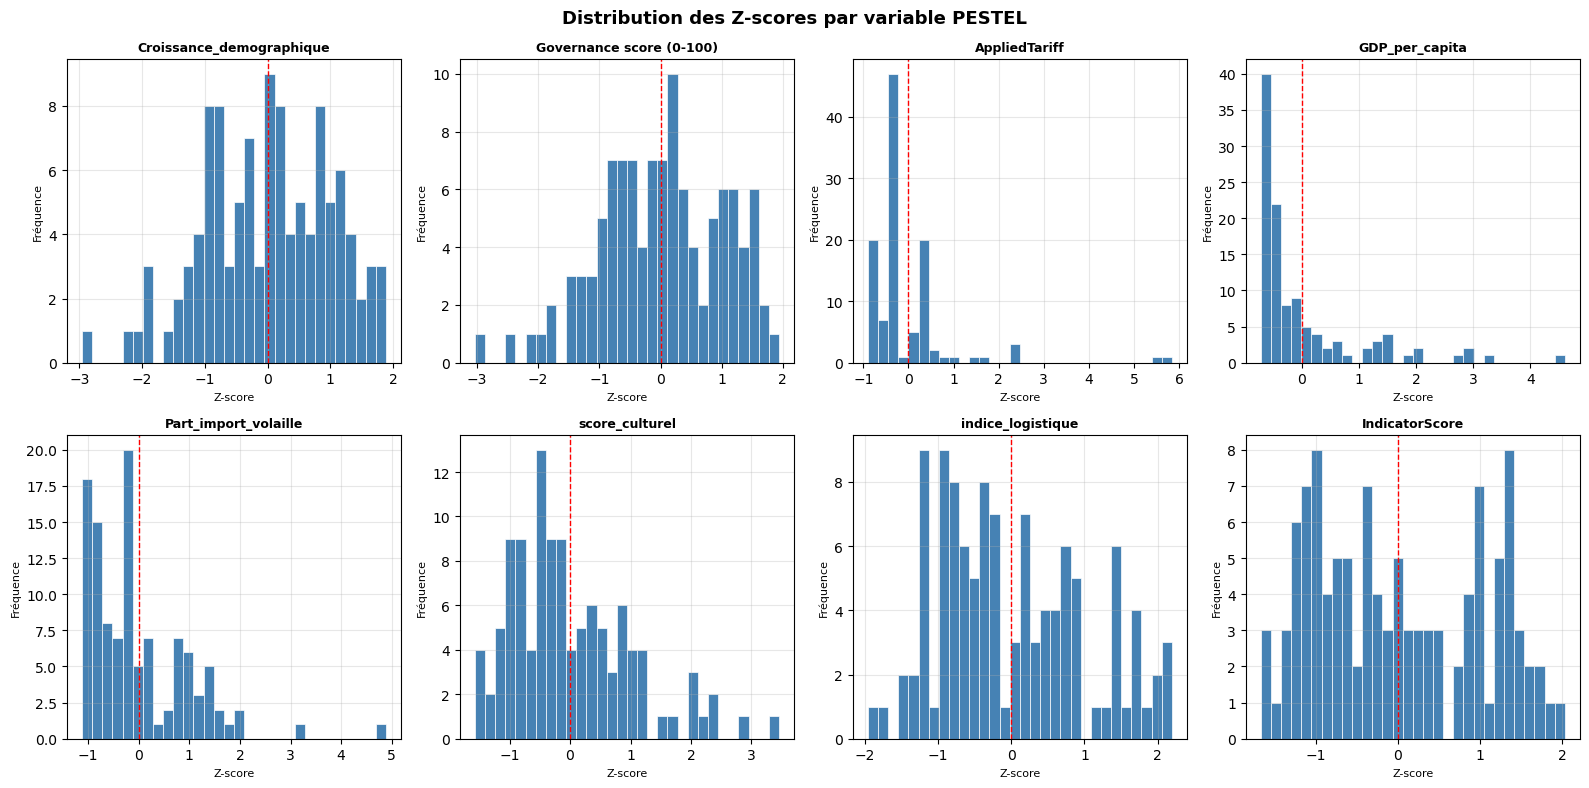

In [9]:
#Visualisation des séries normalisées
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

for i, col in enumerate(cols):
    axes[i].hist(
        X_scaled[:, i],
        bins=30,
        color='steelblue',
        edgecolor='white',
        linewidth=0.5
    )
    axes[i].axvline(0, color='red', linewidth=1, linestyle='--', label='Moyenne')
    axes[i].set_title(col, fontsize=9, fontweight='bold')
    axes[i].set_xlabel('Z-score', fontsize=8)
    axes[i].set_ylabel('Fréquence', fontsize=8)
    axes[i].grid(True, alpha=0.3)

plt.suptitle('Distribution des Z-scores par variable PESTEL', 
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

In [10]:
# ACP complète (8 composantes ici)
pca_full = PCA()
X_pca_full = pca_full.fit_transform(X_scaled)

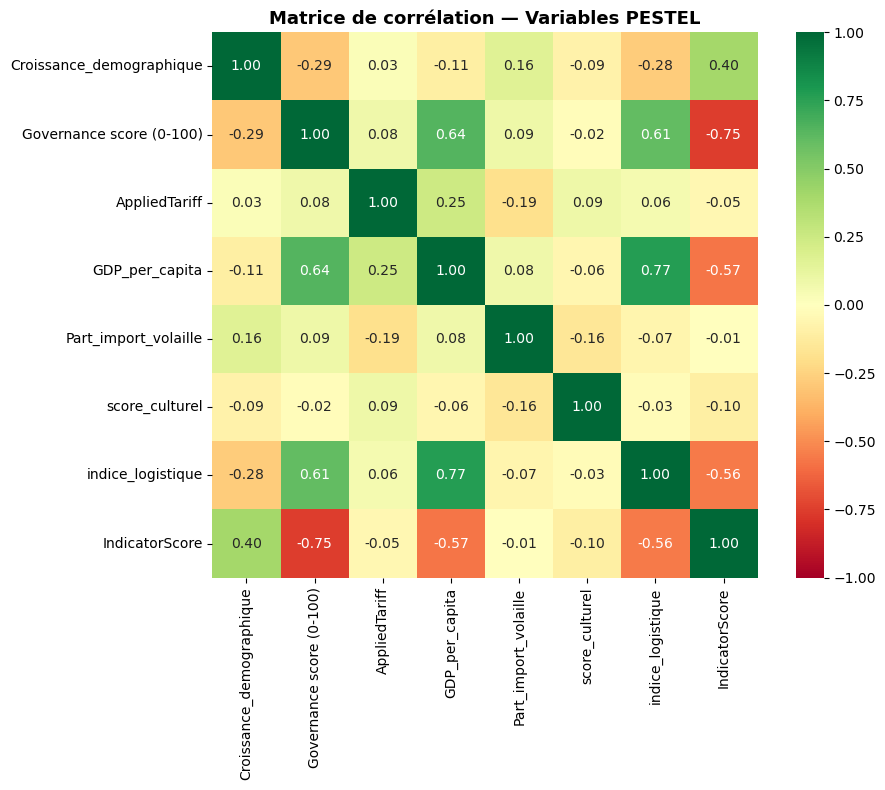

=== Valeurs propres ===
PC1 : 3.1401  (38.9% de variance)
PC2 : 1.3393  (16.6% de variance)
PC3 : 1.1222  (13.9% de variance)
PC4 : 0.8935  (11.1% de variance)
PC5 : 0.6934  (8.6% de variance)
PC6 : 0.4849  (6.0% de variance)
PC7 : 0.2291  (2.8% de variance)
PC8 : 0.1703  (2.1% de variance)

=== Vecteurs propres  ===
                           PC1   PC2   PC3   PC4   PC5   PC6   PC7   PC8
Croissance_demographique -0.25  0.29  0.56 -0.30 -0.53  0.38 -0.05 -0.15
Governance score (0-100)  0.49  0.11 -0.04 -0.08  0.08  0.46  0.72  0.07
AppliedTariff             0.10 -0.38  0.71  0.00  0.55 -0.02  0.01 -0.19
GDP_per_capita            0.48  0.13  0.32 -0.04 -0.18 -0.28 -0.20  0.70
Part_import_volaille     -0.00  0.67 -0.04 -0.49  0.46 -0.27 -0.02 -0.14
score_culturel            0.01 -0.54 -0.16 -0.79 -0.16 -0.15  0.08  0.03
indice_logistique         0.48  0.04  0.06  0.12 -0.38 -0.48  0.09 -0.61
IndicatorScore           -0.48  0.03  0.19  0.12 -0.10 -0.49  0.65  0.21


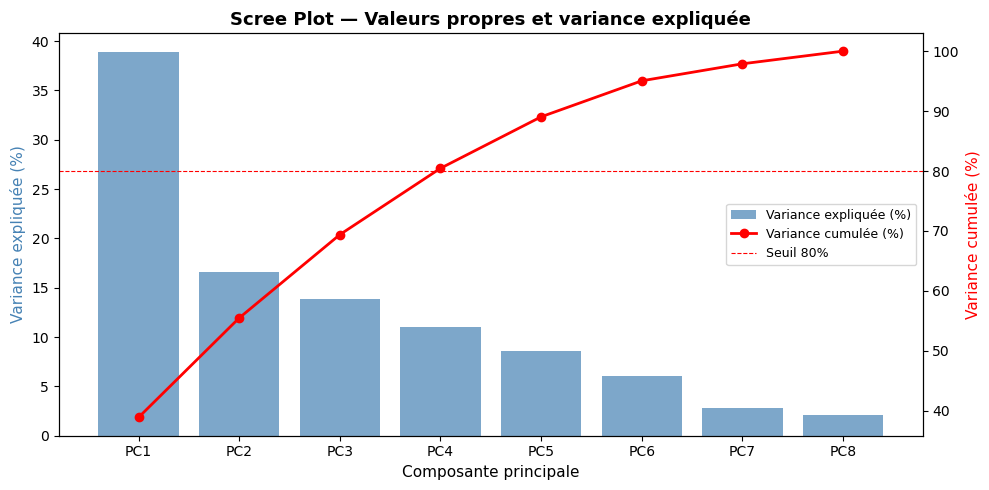

In [11]:
# ==========================
# 1. Matrice de corrélation
# ==========================
df_scaled = pd.DataFrame(X_scaled, columns=cols)
corr_matrix = df_scaled.corr()

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt='.2f',
    cmap='RdYlGn',
    center=0,
    vmin=-1, vmax=1,
    square=True,
    ax=ax
)
ax.set_title('Matrice de corrélation — Variables PESTEL', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

# ==========================
# 2. Valeurs propres et vecteurs propres
# ==========================
# La matrice de corrélation = matrice de covariance après Z-score
cov_matrix = np.cov(X_scaled.T)
valeurs_propres, vecteurs_propres = np.linalg.eig(cov_matrix)

# Tri par ordre décroissant
ordre = np.argsort(valeurs_propres)[::-1]
valeurs_propres = valeurs_propres[ordre]
vecteurs_propres = vecteurs_propres[:, ordre]

print("=== Valeurs propres ===")
for i, vp in enumerate(valeurs_propres):
    print(f"PC{i+1} : {vp:.4f}  ({vp/valeurs_propres.sum()*100:.1f}% de variance)")

print("\n=== Vecteurs propres  ===")
df_vp = pd.DataFrame(
    vecteurs_propres,
    index=cols,
    columns=[f'PC{i+1}' for i in range(len(valeurs_propres))]
)
print(df_vp.round(3))

# ==========================
# 3. Scree plot
# ==========================
variance_expliquee = valeurs_propres / valeurs_propres.sum() * 100
variance_cumulee = variance_expliquee.cumsum()

fig, ax1 = plt.subplots(figsize=(10, 5))

ax1.bar(
    range(1, len(valeurs_propres)+1),
    variance_expliquee,
    color='steelblue',
    alpha=0.7,
    label='Variance expliquée (%)'
)
ax1.set_xlabel('Composante principale', fontsize=11)
ax1.set_ylabel('Variance expliquée (%)', fontsize=11, color='steelblue')

ax2 = ax1.twinx()
ax2.plot(
    range(1, len(valeurs_propres)+1),
    variance_cumulee,
    color='red',
    marker='o',
    linewidth=2,
    label='Variance cumulée (%)'
)
ax2.axhline(y=80, color='red', linewidth=0.8, linestyle='--', label='Seuil 80%')
ax2.set_ylabel('Variance cumulée (%)', fontsize=11, color='red')

ax1.set_title('Scree Plot — Valeurs propres et variance expliquée', fontsize=13, fontweight='bold')
ax1.set_xticks(range(1, len(valeurs_propres)+1))
ax1.set_xticklabels([f'PC{i+1}' for i in range(len(valeurs_propres))])

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='center right', fontsize=9)

plt.tight_layout()
plt.show()

<div style="background-color:#343A40;
            border-left:5px solid RGB(0,150,250);
            padding:15px;
            border-radius:5px;
            margin-top:10px;
            color:white;">

<h3 style="color:white;">Analyse en composantes principales (ACP)</h3>

L'ACP permet de réduire la dimension du jeu de données tout en conservant un maximum d'information. Les huit variables initiales ont été transformées en axes synthétiques appelés <b>composantes principales</b>.

<h3 style="color:white;">Variance expliquée</h3>

Les quatre premiers axes concentrent <b>80 % de la variance totale</b> :

<ul>
<li><b>PC1 :</b> 38,9 %</li>
<li><b>PC2 :</b> 16,6 %</li>
<li><b>PC3 :</b> 13,9 %</li>
<li><b>PC4 :</b> 11,1 %</li>
</ul>

Ces quatre dimensions représentent donc l'essentiel de l'information contenue dans les variables initiales et seront utilisées pour analyser la structure des marchés.

<h3 style="color:white;">Choix méthodologique</h3>

La conservation des quatre premiers axes permet de réduire la complexité du modèle tout en conservant une représentation fidèle des marchés étudiés.

</div>

In [13]:
display(pd.DataFrame(
    pca_full.components_,
    columns=cols,
    index=[f'PC{i}' for i in range(1, len(cols)+1)]
))

,Croissance_demographique,Governance score (0-100),AppliedTariff,GDP_per_capita,Part_import_volaille,score_culturel,indice_logistique,IndicatorScore
PC1,-0.25,0.49,0.10,0.48,-0.00,0.01,0.48,-0.48
PC2,0.29,0.11,-0.38,0.13,0.67,-0.54,0.04,0.03
PC3,0.56,-0.04,0.71,0.32,-0.04,-0.16,0.06,0.19
PC4,0.30,0.08,-0.00,0.04,0.49,0.79,-0.12,-0.12
PC5,-0.53,0.08,0.55,-0.18,0.46,-0.16,-0.38,-0.10
PC6,-0.38,-0.46,0.02,0.28,0.27,0.15,0.48,0.49
PC7,-0.05,0.72,0.01,-0.20,-0.02,0.08,0.09,0.65
PC8,-0.15,0.07,-0.19,0.71,-0.14,0.03,-0.61,0.21


<div style="background-color:#343A40;
            border-left:5px solid RGB(0,150,250);
            padding:15px;
            border-radius:5px;
            margin-top:10px;
            color:white;">

<h3 style="color:white;">Interprétation business des axes principaux</h3>

L'analyse des composantes principales permet de synthétiser les caractéristiques des marchés étudiés selon plusieurs dimensions indépendantes.

<h3 style="color:white;">PC1 — Développement / vulnérabilité (38 %)</h3>

Cet axe représente une opposition entre les marchés présentant une forte capacité structurelle et ceux présentant davantage de vulnérabilités.

<ul>
<li><b>Score élevé :</b> marché plus riche, développé et disposant de meilleures capacités logistiques.</li>

<li><b>Score faible :</b> marché plus vulnérable, avec un niveau de développement inférieur et une croissance démographique plus marquée.</li>
</ul>

<h3 style="color:white;">PC2 — Dépendance structurelle aux imports / consommation culturellement ancrée (16 %)</h3>

Cet axe oppose la dépendance aux importations de volaille et l'ancrage culturel de la consommation.

<ul>
<li><b>Score élevé :</b> forte dépendance aux importations de volaille et dynamique démographique favorable.</li>

<li><b>Score faible :</b> marché avec une demande structurelle de volaille mais davantage protégé par des barrières tarifaires.</li>
</ul>

<h3 style="color:white;">PC3 — Marchés émergents protégés (13 %)</h3>

Cet axe met en évidence des marchés combinant potentiel de développement et niveau de protection commerciale.

<ul>
<li><b>Score élevé :</b> marché présentant un potentiel de croissance mais également des contraintes tarifaires plus importantes.</li>
</ul>

<h3 style="color:white;">PC4 — Ancrage culturel de la volaille (11 %)</h3>

Cet axe isole principalement la dimension culturelle liée à la consommation de volaille.

<ul>
<li><b>Score élevé :</b> marché où la volaille occupe une place importante dans les habitudes alimentaires, traduisant une forte demande structurelle.</li>
</ul>

</div>

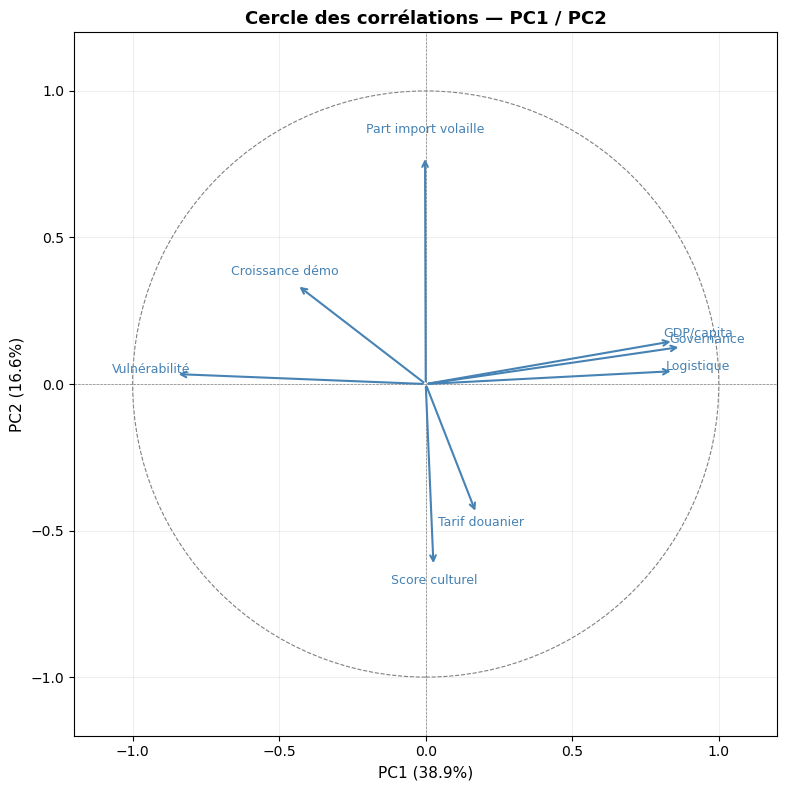

In [15]:
fig, ax = plt.subplots(figsize=(8, 8))

# Cercle unité
cercle = plt.Circle((0, 0), 1, fill=False, color='grey', linewidth=0.8, linestyle='--')
ax.add_patch(cercle)

# Corrélations variables / composantes
# = loadings * sqrt(valeurs propres)
loadings = pca_full.components_.T
sqrt_eigenvalues = np.sqrt(pca_full.explained_variance_)

correlations = loadings * sqrt_eigenvalues

variables = [
    'Croissance démo',
    'Governance',
    'Tarif douanier',
    'GDP/capita',
    'Part import volaille',
    'Score culturel',
    'Logistique',
    'Vulnérabilité'
]

# Tracé des flèches
for i, var in enumerate(variables):
    ax.annotate(
        '',
        xy=(correlations[i, 0], correlations[i, 1]),
        xytext=(0, 0),
        arrowprops=dict(arrowstyle='->', color='steelblue', lw=1.5)
    )
    ax.text(
        correlations[i, 0] * 1.1,
        correlations[i, 1] * 1.1,
        var,
        fontsize=9,
        ha='center',
        color='steelblue'
    )

# Axes
ax.axhline(0, color='grey', linewidth=0.5, linestyle='--')
ax.axvline(0, color='grey', linewidth=0.5, linestyle='--')
ax.set_xlim(-1.2, 1.2)
ax.set_ylim(-1.2, 1.2)
ax.set_xlabel(f'PC1 ({pca_full.explained_variance_ratio_[0]*100:.1f}%)', fontsize=11)
ax.set_ylabel(f'PC2 ({pca_full.explained_variance_ratio_[1]*100:.1f}%)', fontsize=11)
ax.set_title('Cercle des corrélations — PC1 / PC2', fontsize=13, fontweight='bold')
ax.set_aspect('equal')
ax.grid(True, alpha=0.2)

plt.tight_layout()
plt.show()

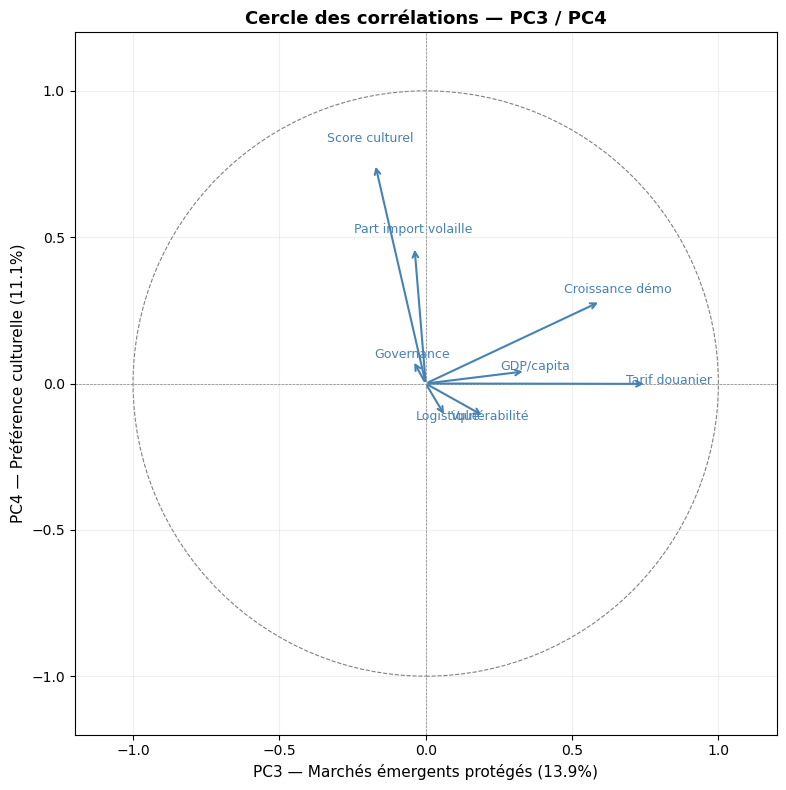

In [16]:
fig, ax = plt.subplots(figsize=(8, 8))

# Cercle unité
cercle = plt.Circle((0, 0), 1, fill=False, color='grey', linewidth=0.8, linestyle='--')
ax.add_patch(cercle)

# Corrélations variables / composantes PC3 et PC4 (indices 2 et 3)
loadings = pca_full.components_.T
sqrt_eigenvalues = np.sqrt(pca_full.explained_variance_)

correlations = loadings * sqrt_eigenvalues

variables = [
    'Croissance démo',
    'Governance',
    'Tarif douanier',
    'GDP/capita',
    'Part import volaille',
    'Score culturel',
    'Logistique',
    'Vulnérabilité'
]

# Tracé des flèches sur PC3 (indice 2) et PC4 (indice 3)
for i, var in enumerate(variables):
    ax.annotate(
        '',
        xy=(correlations[i, 2], correlations[i, 3]),
        xytext=(0, 0),
        arrowprops=dict(arrowstyle='->', color='steelblue', lw=1.5)
    )
    ax.text(
        correlations[i, 2] * 1.1,
        correlations[i, 3] * 1.1,
        var,
        fontsize=9,
        ha='center',
        color='steelblue'
    )

# Axes
ax.axhline(0, color='grey', linewidth=0.5, linestyle='--')
ax.axvline(0, color='grey', linewidth=0.5, linestyle='--')
ax.set_xlim(-1.2, 1.2)
ax.set_ylim(-1.2, 1.2)
ax.set_xlabel(f'PC3 — Marchés émergents protégés ({pca_full.explained_variance_ratio_[2]*100:.1f}%)', fontsize=11)
ax.set_ylabel(f'PC4 — Préférence culturelle ({pca_full.explained_variance_ratio_[3]*100:.1f}%)', fontsize=11)
ax.set_title('Cercle des corrélations — PC3 / PC4', fontsize=13, fontweight='bold')
ax.set_aspect('equal')
ax.grid(True, alpha=0.2)

plt.tight_layout()
plt.show()

<div style="background-color:#343A40;
            border-left:5px solid RGB(0,150,250);
            padding:15px;
            border-radius:5px;
            margin-top:10px;
            color:white;">

<h3 style="color:white;">Construction d'un score d'opportunité nette</h3>

L'analyse des scores de variance et du cercle de corrélation met en évidence une opportunité de simplification du modèle.

L'axe <b>PC3</b> représente principalement des marchés caractérisés par de fortes barrières à l'entrée, malgré la présence d'une certaine dynamique démographique. L'analyse de la matrice de corrélation montre que cet axe reste faiblement corrélé aux autres dimensions du modèle (<b>corrélation absolue inférieure à 0,20</b>), ce qui indique qu'il apporte une information spécifique.

L'axe <b>PC4</b> représente quant à lui principalement la dimension liée au <b>score culturel</b>, avec une contribution secondaire de la dépendance aux importations. Comme pour PC3, cet axe présente une faible corrélation avec les autres composantes (<b>corrélation absolue inférieure à 0,20</b>), ce qui confirme son caractère complémentaire.

Afin de conserver un maximum d'information tout en facilitant la visualisation des marchés sur un unique biplot basé sur <b>PC1 et PC2</b>, un <b>score d'opportunité nette</b> sera construit :

<br>

<center>
<b>Score d'opportunité nette = PC4 (demande structurelle) - PC3 (contrainte du marché)</b>
</center>

<br>

Ce score permet d'intégrer simultanément l'attractivité culturelle du marché et les contraintes commerciales identifiées par l'ACP.

</div>

Sur la figure suivante le code couleur représente le score d'opportunité nette : il combine positivement la préférence culturelle pour la volaille (PC4) et négativement les barrières de marché — tarifs douaniers et protection locale (PC3). Un pays vert présente une forte demande culturelle avec peu de barrières à l'entrée.

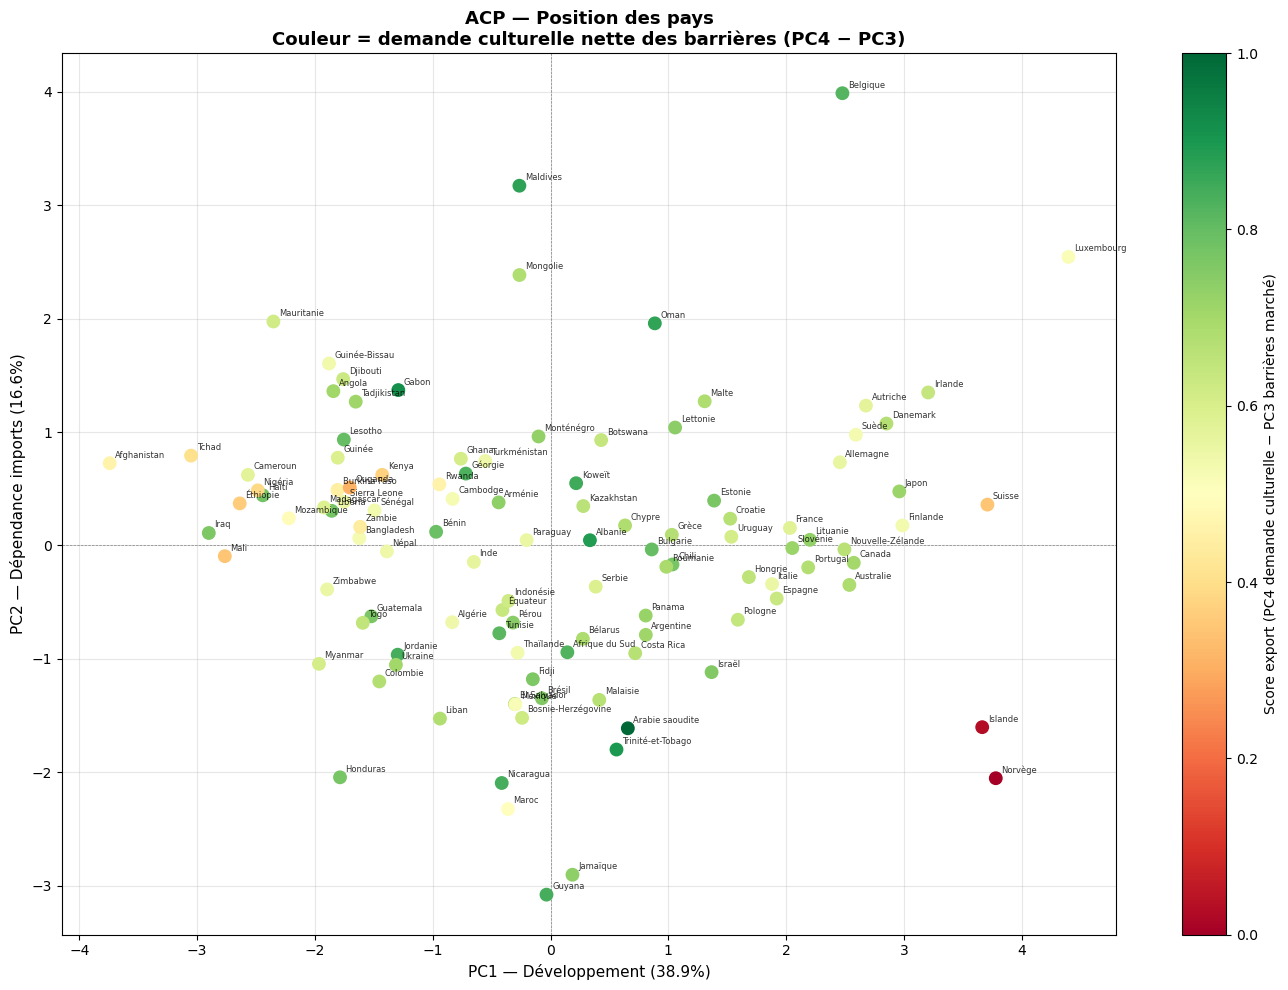

In [19]:

# ==========================
# 1. Calcul du score PC4 - PC3
# ==========================
score_export = X_pca_full[:, 3] - X_pca_full[:, 2]

# Normalisation entre 0 et 1
score_norm = (
    score_export - score_export.min()
) / (
    score_export.max() - score_export.min()
)

# Noms des pays
noms_pays = df_final_short.loc[X.index, 'Nom français'].values

# ==========================
# 2. Biplot PC1 / PC2 coloré
# ==========================
fig, ax = plt.subplots(figsize=(14, 10))

scatter = ax.scatter(
    X_pca_full[:, 0],
    X_pca_full[:, 1],
    c=score_norm,
    cmap='RdYlGn',
    s=80,
    zorder=3
)

# Barre de couleur
cbar = plt.colorbar(scatter, ax=ax)
cbar.set_label(
    'Score export (PC4 demande culturelle − PC3 barrières marché)',
    fontsize=10
)

# Annotation des pays
for i, pays in enumerate(noms_pays):
    ax.annotate(
        pays,
        (X_pca_full[i, 0], X_pca_full[i, 1]),
        fontsize=6,
        alpha=0.8,
        xytext=(4, 4),
        textcoords='offset points'
    )

# Axes
ax.axhline(0, color='grey', linewidth=0.5, linestyle='--')
ax.axvline(0, color='grey', linewidth=0.5, linestyle='--')
ax.set_xlabel(
    f'PC1 — Développement ({pca_full.explained_variance_ratio_[0]*100:.1f}%)',
    fontsize=11
)
ax.set_ylabel(
    f'PC2 — Dépendance imports ({pca_full.explained_variance_ratio_[1]*100:.1f}%)',
    fontsize=11
)
ax.set_title(
    'ACP — Position des pays\nCouleur = demande culturelle nette des barrières (PC4 − PC3)',
    fontsize=13,
    fontweight='bold'
)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

<div style="background-color:#343A40;
            border-left:5px solid RGB(0,150,250);
            padding:15px;
            border-radius:5px;
            margin-top:10px;
            color:white;">

<h3 style="color:white;">Lecture du biplot et identification des opportunités</h3>

Le graphique permet une lecture fine de la position relative des marchés selon les deux premiers axes de l'ACP, tout en intégrant le score d'opportunité nette construit précédemment.

<h3 style="color:white;">Axe 1 — Niveau de développement des marchés</h3>

L'axe horizontal répartit les pays selon un gradient de développement structurel.

On observe que les scores d'<b>opportunité nette</b> les plus faibles se situent principalement aux extrémités de cet axe, indiquant que les marchés très éloignés du profil central présentent davantage de contraintes ou un potentiel moins favorable.

<h3 style="color:white;">Axe 2 — Dépendance aux importations et ancrage de la consommation</h3>

L'axe vertical oppose deux profils de marchés :

<ul>
<li><b>En haut de l'axe :</b> des pays fortement dépendants aux importations mais où la consommation de volaille est moins ancrée culturellement (exemple : Mongolie, marché davantage orienté vers une consommation traditionnelle de mouton).</li>

<li><b>En bas de l'axe :</b> des pays où la demande en volaille est plus forte et structurellement intégrée aux habitudes alimentaires (exemple : Arabie Saoudite).</li>
</ul>

<h3 style="color:white;">Identification des marchés à potentiel</h3>

Les scores d'opportunité nette les plus élevés se concentrent principalement autour du centre du plan factoriel et dans la partie basse de l'axe 2.

Parmi les marchés présentant les profils les plus intéressants figurent notamment :

<b>Albanie, Tunisie, Jordanie, Nicaragua, Guyane, Arabie Saoudite, Trinité-et-Tobago, Pérou, Brésil</b>, etc.

</div>

Maintenant on va réaliser une CAH sur les données des quatres premiers axes.

On va utiliser la méthode de Ward qui minimise la variance intra-cluster et la distance euclidienne (distance à vol d'oiseau dans un espace euclidien)

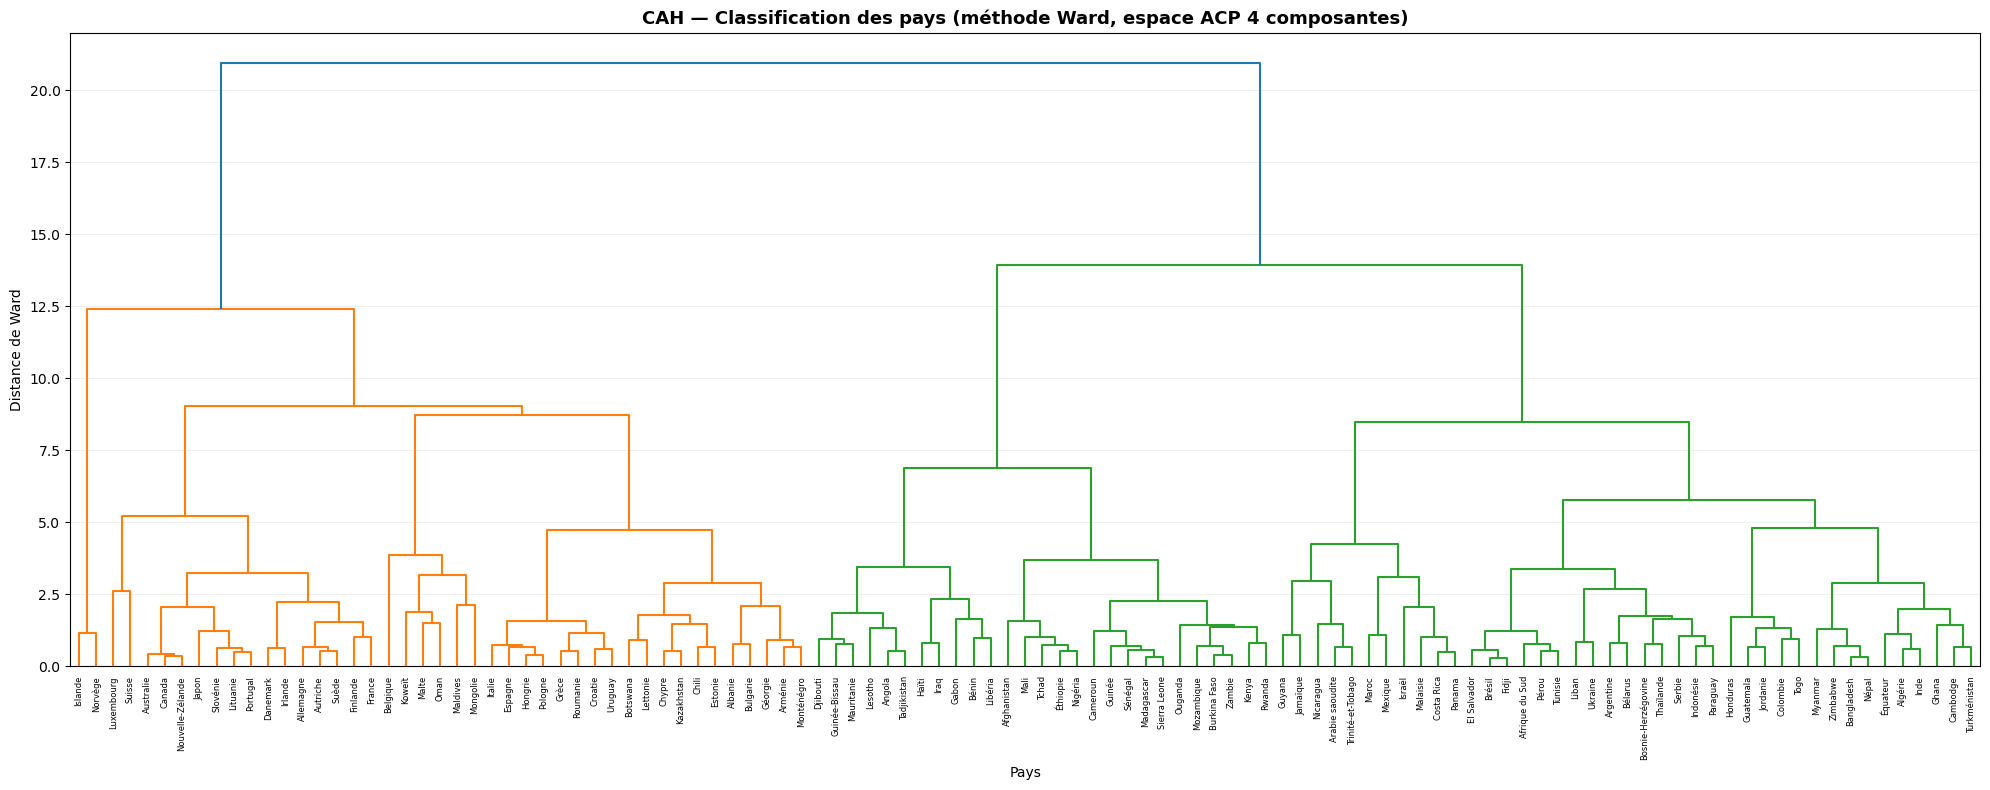

In [22]:


# ==========================
# 1. CAH sur les 4 premières composantes ACP
# ==========================
X_cah = X_pca_full[:, :4]

Z = linkage(X_cah, method='ward', metric='euclidean')

# ==========================
# 2. Dendrogramme
# ==========================
noms_pays = df_final_short.loc[X.index, 'Nom français'].values

fig, ax = plt.subplots(figsize=(20, 8))

dendrogram(
    Z,
    labels=noms_pays,
    leaf_rotation=90,
    leaf_font_size=6,
    ax=ax
)

ax.set_title('CAH — Classification des pays (méthode Ward, espace ACP 4 composantes)', 
             fontsize=13, fontweight='bold')
ax.set_xlabel('Pays', fontsize=10)
ax.set_ylabel('Distance de Ward', fontsize=10)
ax.grid(True, alpha=0.2, axis='y')

plt.tight_layout()
plt.show()

On va regarder ce que ça donne avec quatre clusters :

In [24]:
# Voir la composition réelle des 4 clusters
n_clusters = 4
labels_clusters = fcluster(Z, n_clusters, criterion='maxclust')

df_clusters = pd.DataFrame({
    'Pays': noms_pays,
    'Cluster': labels_clusters
}).sort_values('Cluster')

for c in range(1, n_clusters + 1):
    pays_cluster = df_clusters[df_clusters['Cluster'] == c]['Pays'].tolist()
    print(f"\n--- Cluster {c} ({len(pays_cluster)} pays) ---")
    print(', '.join(pays_cluster))


--- Cluster 1 (2 pays) ---
Islande, Norvège

--- Cluster 2 (41 pays) ---
Italie, Nouvelle-Zélande, Croatie, Kazakhstan, Espagne, Estonie, Monténégro, Mongolie, Finlande, France, Géorgie, Malte, Grèce, Maldives, Luxembourg, Lituanie, Hongrie, Lettonie, Koweït, Irlande, Oman, Chypre, Danemark, Canada, Uruguay, Albanie, Allemagne, Suisse, Suède, Arménie, Australie, Chili, Slovénie, Belgique, Autriche, Bulgarie, Pologne, Portugal, Roumanie, Japon, Botswana

--- Cluster 3 (27 pays) ---
Mali, Mozambique, Madagascar, Nigéria, Sénégal, Libéria, Tadjikistan, Rwanda, Lesotho, Tchad, Mauritanie, Ouganda, Kenya, Sierra Leone, Afghanistan, Angola, Éthiopie, Cameroun, Guinée, Guinée-Bissau, Bénin, Gabon, Haïti, Djibouti, Burkina Faso, Iraq, Zambie

--- Cluster 4 (41 pays) ---
Brésil, Serbie, Bélarus, Cambodge, Bosnie-Herzégovine, Bangladesh, Jordanie, Arabie saoudite, Algérie, Thaïlande, Togo, Trinité-et-Tobago, Tunisie, Turkménistan, Ukraine, Afrique du Sud, Argentine, Pérou, Costa Rica, Panama, I

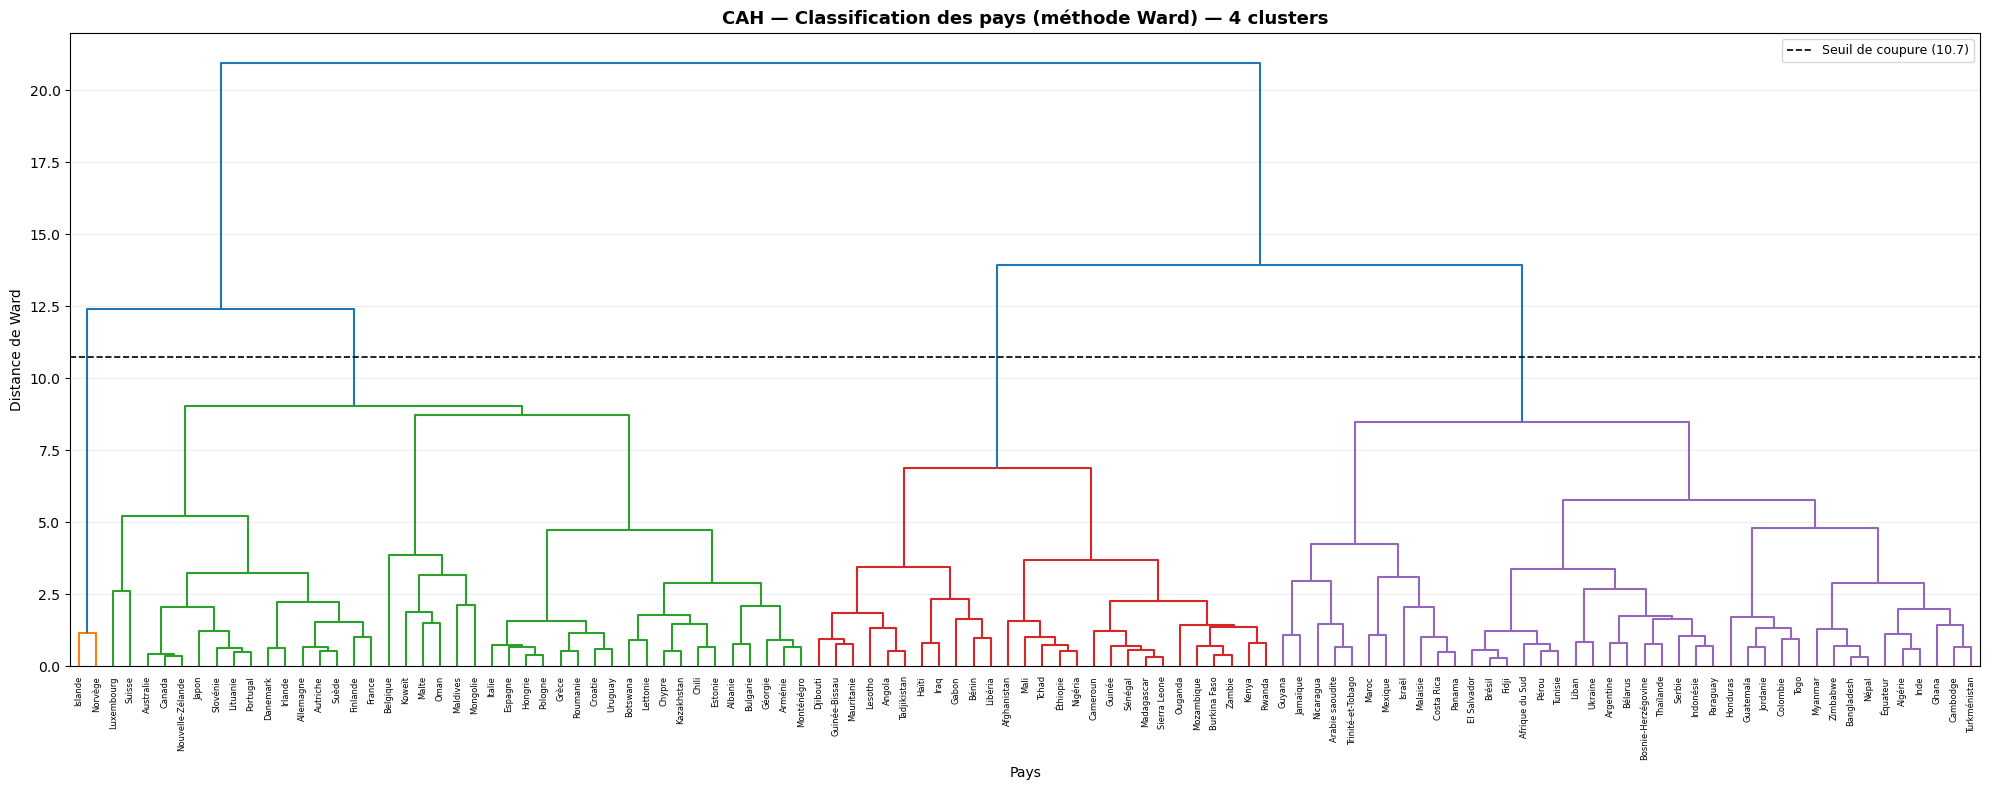

In [25]:

# ==========================
# Dendrogramme avec 4 clusters forcés
# ==========================

# Calculer le seuil correspondant à 4 clusters
# On prend la hauteur entre la 4ème et 5ème fusion en partant du haut
seuil = (Z[-3, 2] + Z[-4, 2]) / 2  # moyenne entre les deux sauts concernés

fig, ax = plt.subplots(figsize=(20, 8))

dendrogram(
    Z,
    labels=noms_pays,
    leaf_rotation=90,
    leaf_font_size=6,
    color_threshold=seuil,
    ax=ax
)

# Ligne de coupe
ax.axhline(y=seuil, color='black', linewidth=1.2, linestyle='--', label=f'Seuil de coupure ({seuil:.1f})')
ax.legend(fontsize=9)

ax.set_title('CAH — Classification des pays (méthode Ward) — 4 clusters', 
             fontsize=13, fontweight='bold')
ax.set_xlabel('Pays', fontsize=10)
ax.set_ylabel('Distance de Ward', fontsize=10)
ax.grid(True, alpha=0.2, axis='y')

plt.tight_layout()
plt.show()

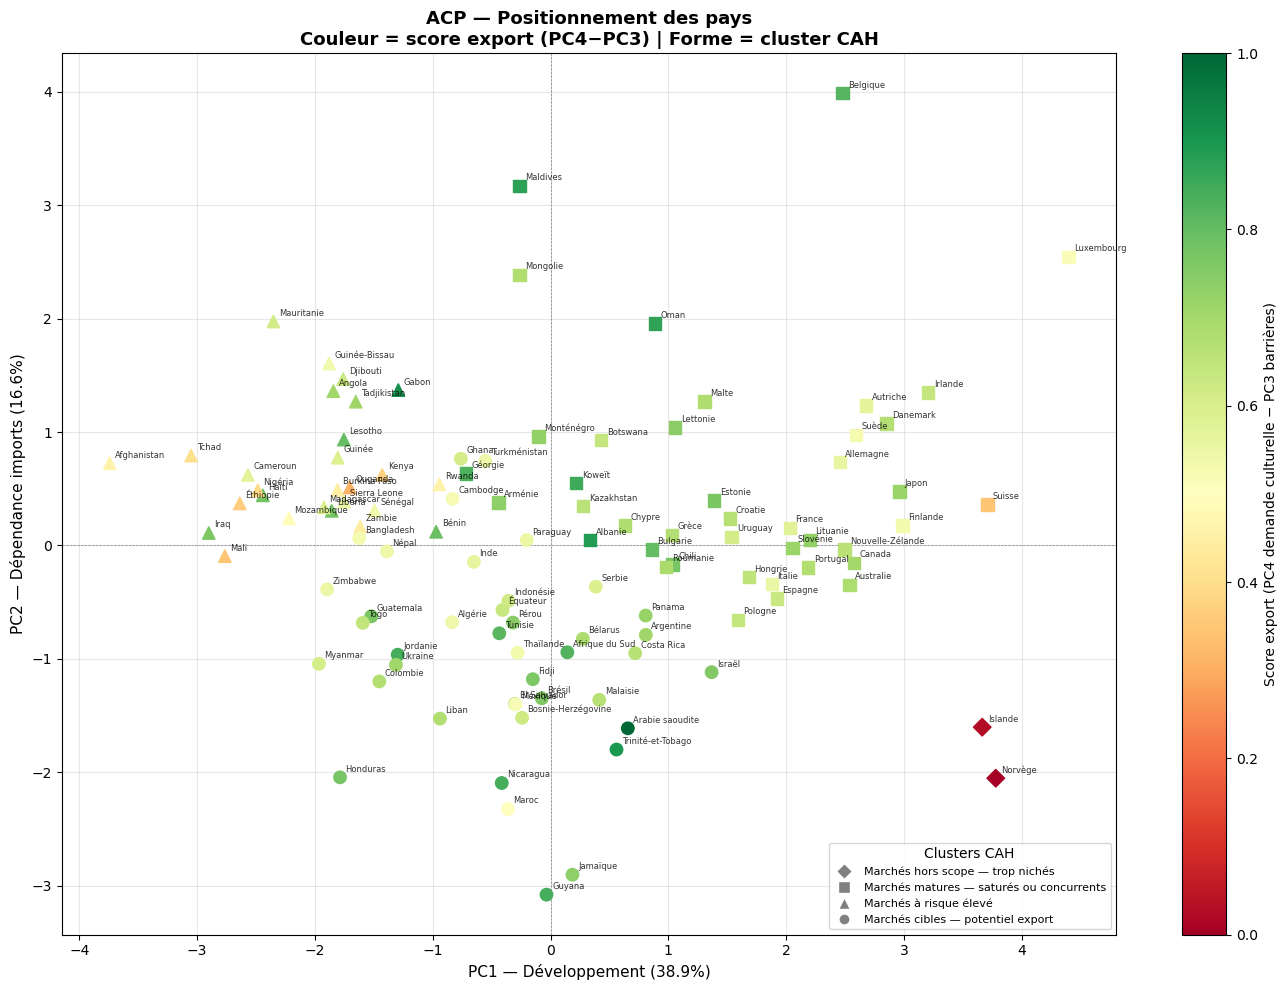

In [26]:
fig, ax = plt.subplots(figsize=(14, 10))

# ==========================
# 1. Calcul du score PC4 - PC3
# ==========================
score_export = X_pca_full[:, 3] - X_pca_full[:, 2]
score_norm = (score_export - score_export.min()) / (score_export.max() - score_export.min())

# ==========================
# 2. Clusters
# ==========================
n_clusters = 4
labels_clusters = fcluster(Z, n_clusters, criterion='maxclust')

# Formes et noms des clusters
cluster_markers = {
    1: 'D',
    2: 's',
    3: '^',
    4: 'o'
}

cluster_labels = {
    1: 'Marchés hors scope — trop nichés',
    2: 'Marchés matures — saturés ou concurrents',
    3: 'Marchés à risque élevé',
    4: 'Marchés cibles — potentiel export'
}

# ==========================
# 3. Scatter par cluster — forme + couleur score
# ==========================
from matplotlib.lines import Line2D

for c, marker in cluster_markers.items():
    mask = labels_clusters == c
    scatter = ax.scatter(
        X_pca_full[mask, 0],
        X_pca_full[mask, 1],
        c=score_norm[mask],
        cmap='RdYlGn',
        vmin=0, vmax=1,      # même échelle pour tous les clusters
        marker=marker,
        s=80,
        zorder=3
    )

# Colorbar — on l'attache au dernier scatter
cbar = plt.colorbar(scatter, ax=ax)
cbar.set_label('Score export (PC4 demande culturelle − PC3 barrières)', fontsize=10)

# ==========================
# 4. Annotations pays
# ==========================
for i, pays in enumerate(noms_pays):
    ax.annotate(
        pays,
        (X_pca_full[i, 0], X_pca_full[i, 1]),
        fontsize=6,
        alpha=0.8,
        xytext=(4, 4),
        textcoords='offset points'
    )

# ==========================
# 5. Légende clusters
# ==========================
legend_elements = [
    Line2D([0], [0],
           marker=cluster_markers[c],
           color='w',
           markerfacecolor='grey',
           markersize=8,
           label=cluster_labels[c])
    for c in cluster_markers
]
ax.legend(handles=legend_elements, loc='lower right', fontsize=8, title='Clusters CAH')

# ==========================
# 6. Axes et mise en forme
# ==========================
ax.axhline(0, color='grey', linewidth=0.5, linestyle='--')
ax.axvline(0, color='grey', linewidth=0.5, linestyle='--')
ax.set_xlabel(f'PC1 — Développement ({pca_full.explained_variance_ratio_[0]*100:.1f}%)', fontsize=11)
ax.set_ylabel(f'PC2 — Dépendance imports ({pca_full.explained_variance_ratio_[1]*100:.1f}%)', fontsize=11)
ax.set_title(
    'ACP — Positionnement des pays\nCouleur = score export (PC4−PC3) | Forme = cluster CAH',
    fontsize=13, fontweight='bold'
)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

<div style="background-color:#343A40;
            border-left:5px solid RGB(0,150,250);
            padding:15px;
            border-radius:5px;
            margin-top:10px;
            color:white;">

<h3 style="color:white;">Comparaison des classifications</h3>

Afin de vérifier la cohérence des groupes identifiés, les résultats obtenus avec la <b>Classification Ascendante Hiérarchique (CAH)</b> seront comparés avec ceux obtenus par une méthode de <b>K-moyennes</b>.

</div>

C:\Users\victo\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\victo\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\victo\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\victo\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Window

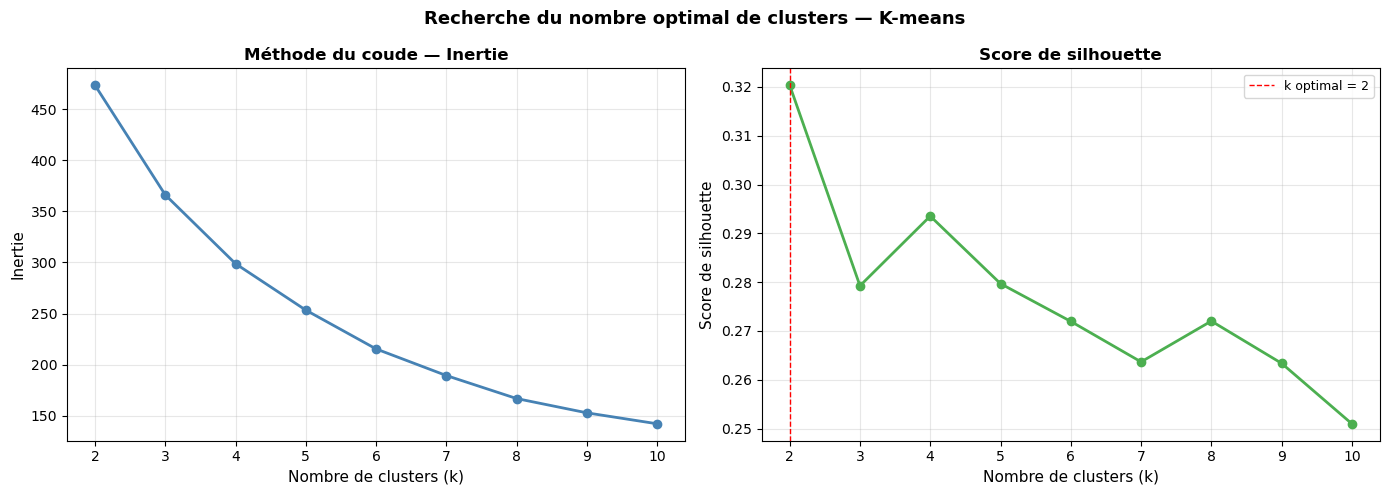


K optimal selon silhouette : 2

Scores de silhouette par k :
  k=2 : 0.3203
  k=3 : 0.2792
  k=4 : 0.2935
  k=5 : 0.2797
  k=6 : 0.2720
  k=7 : 0.2637
  k=8 : 0.2720
  k=9 : 0.2634
  k=10 : 0.2510


In [28]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt
import numpy as np

# On travaille sur les 4 composantes ACP
X_kmeans = X_pca_full[:, :4]

# ==========================
# 1. Calcul inertie + silhouette pour k de 2 à 10
# ==========================
k_range = range(2, 11)
inerties = []
silhouettes = []

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_kmeans)
    inerties.append(km.inertia_)
    silhouettes.append(silhouette_score(X_kmeans, labels))

# ==========================
# 2. Graphiques côte à côte
# ==========================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Courbe d'inertie
ax1.plot(k_range, inerties, marker='o', color='steelblue', linewidth=2)
ax1.set_xlabel('Nombre de clusters (k)', fontsize=11)
ax1.set_ylabel('Inertie', fontsize=11)
ax1.set_title('Méthode du coude — Inertie', fontsize=12, fontweight='bold')
ax1.set_xticks(list(k_range))
ax1.grid(True, alpha=0.3)

# Score de silhouette
ax2.plot(k_range, silhouettes, marker='o', color='#4CAF50', linewidth=2)
ax2.set_xlabel('Nombre de clusters (k)', fontsize=11)
ax2.set_ylabel('Score de silhouette', fontsize=11)
ax2.set_title('Score de silhouette', fontsize=12, fontweight='bold')
ax2.set_xticks(list(k_range))
ax2.grid(True, alpha=0.3)

# Marquer le maximum de silhouette
k_optimal = list(k_range)[np.argmax(silhouettes)]
ax2.axvline(x=k_optimal, color='red', linewidth=1, linestyle='--',
            label=f'k optimal = {k_optimal}')
ax2.legend(fontsize=9)

plt.suptitle('Recherche du nombre optimal de clusters — K-means',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

print(f"\nK optimal selon silhouette : {k_optimal}")
print("\nScores de silhouette par k :")
for k, s in zip(k_range, silhouettes):
    print(f"  k={k} : {s:.4f}")

<div style="background-color:#343A40;
            border-left:5px solid RGB(0,150,250);
            padding:15px;
            border-radius:5px;
            margin-top:10px;
            color:white;">

<h3 style="color:white;">Choix du nombre de clusters</h3>

Le score de silhouette identifie <b>k = 2</b> comme la segmentation optimale au sens strict du critère statistique.

Cependant, <b>k = 4</b> présente également un second optimum local avec un score de silhouette de <b>0,297</b>. Cette segmentation offre une granularité plus fine et permet de distinguer des profils de marchés plus homogènes d'un point de vue business.

Le choix de <b>4 clusters</b> est donc retenu car il apporte un niveau de détail plus pertinent pour la prise de décision export, tout en conservant une cohérence statistique acceptable.

</div>

In [30]:

# ==========================
# K-means optimisé
# ==========================
km_optimise = KMeans(
    n_clusters=4,
    init='k-means++',    # initialisation intelligente
    n_init=50,           # 50 initialisations différentes
    max_iter=500,        # assez d'itérations pour converger
    tol=1e-6,            # tolérance de convergence stricte
    random_state=42      # reproductibilité
)

labels_kmeans = km_optimise.fit_predict(X_pca_full[:, :4])

print(f"Inertie finale       : {km_optimise.inertia_:.4f}")
print(f"Nombre d'itérations  : {km_optimise.n_iter_}")
print(f"Méthode init         : k-means++")
print(f"Nombre d'essais      : 50")

# Comparaison avec version basique
km_basique = KMeans(
    n_clusters=4,
    init='random',
    n_init=10,
    max_iter=300,
    random_state=42
)
km_basique.fit(X_pca_full[:, :4])

print(f"\n--- Comparaison ---")
print(f"Inertie basique      : {km_basique.inertia_:.4f}")
print(f"Inertie optimisée    : {km_optimise.inertia_:.4f}")
print(f"Gain                 : {(km_basique.inertia_ - km_optimise.inertia_):.4f}")

C:\Users\victo\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


Inertie finale       : 298.3268
Nombre d'itérations  : 5
Méthode init         : k-means++
Nombre d'essais      : 50

--- Comparaison ---
Inertie basique      : 298.8816
Inertie optimisée    : 298.3268
Gain                 : 0.5547


C:\Users\victo\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


In [31]:

# ==========================
# 1. K-means k=4
# ==========================
from sklearn.cluster import KMeans
import numpy as np

# ==========================
# K-means optimisé
# ==========================
km_optimise = KMeans(
    n_clusters=4,
    init='k-means++',    # initialisation intelligente
    n_init=50,           # 50 initialisations différentes
    max_iter=500,        # assez d'itérations pour converger
    tol=1e-6,            # tolérance de convergence stricte
    random_state=42      # reproductibilité
)

labels_kmeans = km_optimise.fit_predict(X_pca_full[:, :4])

print(f"Inertie finale       : {km_optimise.inertia_:.4f}")
print(f"Nombre d'itérations  : {km_optimise.n_iter_}")
print(f"Méthode init         : k-means++")
print(f"Nombre d'essais      : 50")

# Comparaison avec version basique
km_basique = KMeans(
    n_clusters=4,
    init='random',
    n_init=10,
    max_iter=300,
    random_state=42
)
km_basique.fit(X_pca_full[:, :4])

print(f"\n--- Comparaison ---")
print(f"Inertie basique      : {km_basique.inertia_:.4f}")
print(f"Inertie optimisée    : {km_optimise.inertia_:.4f}")
print(f"Gain                 : {(km_basique.inertia_ - km_optimise.inertia_):.4f}")

# ==========================
# 2. Calcul du score PC4 - PC3
# ==========================
score_export = X_pca_full[:, 3] - X_pca_full[:, 2]
score_norm = (score_export - score_export.min()) / (score_export.max() - score_export.min())

# ==========================
# 3. Composition des clusters
# ==========================
df_kmeans = pd.DataFrame({
    'Pays': noms_pays,
    'Cluster': labels_kmeans
}).sort_values('Cluster')

for c in sorted(df_kmeans['Cluster'].unique()):
    pays_cluster = df_kmeans[df_kmeans['Cluster'] == c]['Pays'].tolist()
    print(f"\n--- Cluster {c} ({len(pays_cluster)} pays) ---")
    print(', '.join(pays_cluster))

C:\Users\victo\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


Inertie finale       : 298.3268
Nombre d'itérations  : 5
Méthode init         : k-means++
Nombre d'essais      : 50

--- Comparaison ---
Inertie basique      : 298.8816
Inertie optimisée    : 298.3268
Gain                 : 0.5547

--- Cluster 0 (43 pays) ---
El Salvador, Pérou, Paraguay, Liban, Équateur, Panama, Fidji, Nicaragua, Géorgie, Monténégro, Guatemala, Mexique, Guyana, Honduras, Maroc, Inde, Indonésie, Malaisie, Israël, Jamaïque, Jordanie, Kazakhstan, Costa Rica, Colombie, Koweït, Chili, Trinité-et-Tobago, Argentine, Chypre, Bélarus, Thaïlande, Arabie saoudite, Bénin, Arménie, Bosnie-Herzégovine, Brésil, Bulgarie, Algérie, Serbie, Albanie, Afrique du Sud, Ukraine, Tunisie

--- Cluster 1 (36 pays) ---
Turkménistan, Madagascar, Maldives, Mali, Libéria, Mongolie, Togo, Mozambique, Myanmar, Népal, Tchad, Nigéria, Ouganda, Tadjikistan, Sierra Leone, Rwanda, Sénégal, Mauritanie, Afghanistan, Zimbabwe, Bangladesh, Kenya, Cameroun, Cambodge, Angola, Zambie, Burkina Faso, Djibouti, Ir

C:\Users\victo\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


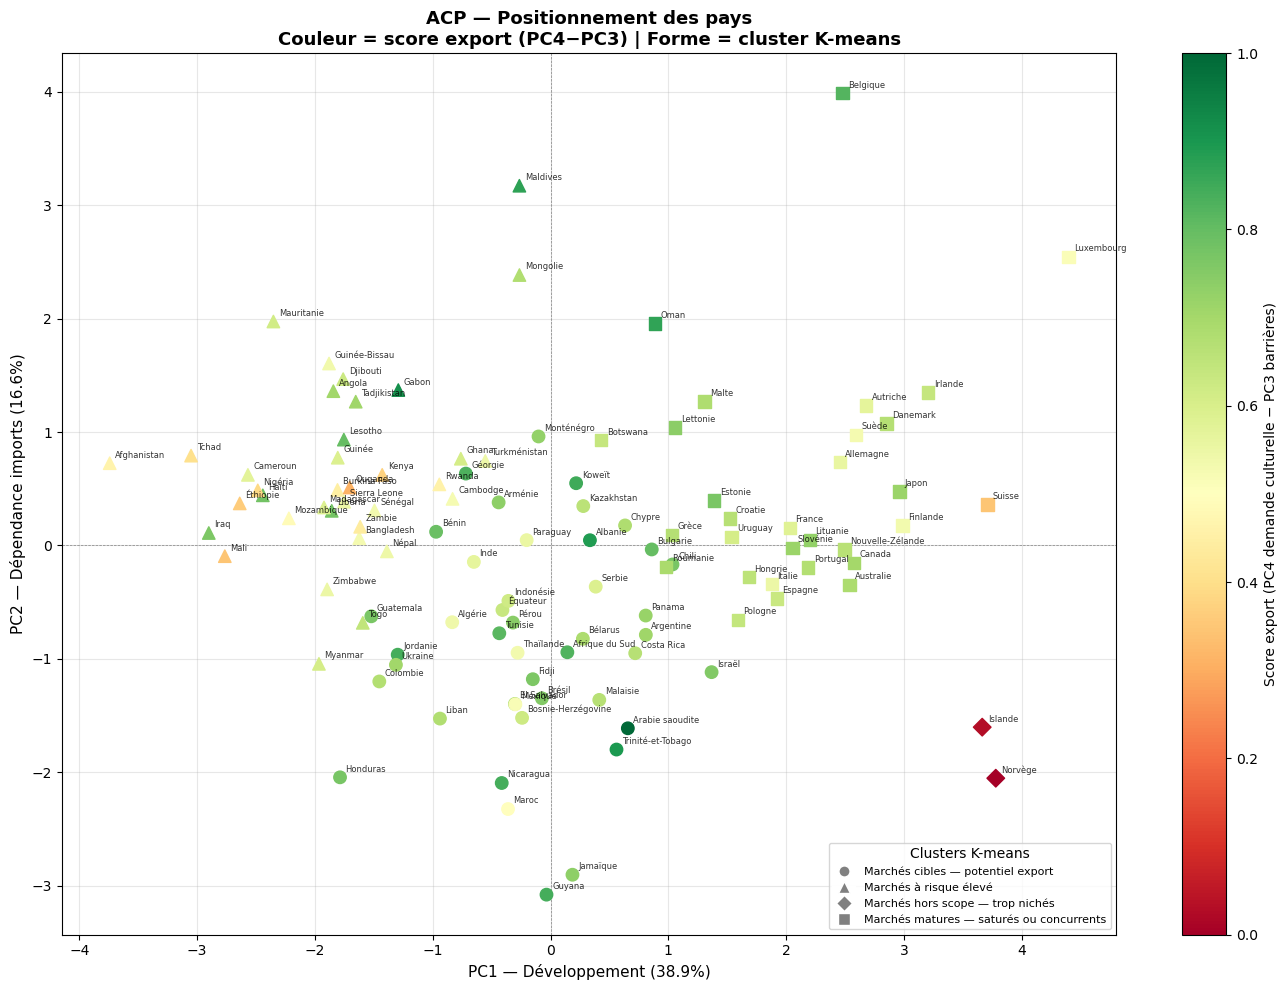

In [32]:
fig, ax = plt.subplots(figsize=(14, 10))

# ==========================
# Formes et labels — indexés sur 0
# ==========================
cluster_markers = {0: 'o', 1: '^', 2: 'D', 3: 's'}
cluster_labels = {
    0: 'Marchés cibles — potentiel export',
    1: 'Marchés à risque élevé',
    2: 'Marchés hors scope — trop nichés',
    3: 'Marchés matures — saturés ou concurrents'
}

# ==========================
# Scatter par cluster
# ==========================
for c, marker in cluster_markers.items():
    mask = labels_kmeans == c
    scatter = ax.scatter(
        X_pca_full[mask, 0],
        X_pca_full[mask, 1],
        c=score_norm[mask],
        cmap='RdYlGn',
        vmin=0, vmax=1,
        marker=marker,
        s=80,
        zorder=3
    )

# Colorbar
cbar = plt.colorbar(scatter, ax=ax)
cbar.set_label('Score export (PC4 demande culturelle − PC3 barrières)', fontsize=10)

# Annotations pays
for i, pays in enumerate(noms_pays):
    ax.annotate(
        pays,
        (X_pca_full[i, 0], X_pca_full[i, 1]),
        fontsize=6,
        alpha=0.8,
        xytext=(4, 4),
        textcoords='offset points'
    )

# Légende
legend_elements = [
    Line2D([0], [0],
           marker=cluster_markers[c],
           color='w',
           markerfacecolor='grey',
           markersize=8,
           label=cluster_labels[c])
    for c in cluster_markers
]
ax.legend(handles=legend_elements, loc='lower right', fontsize=8, title='Clusters K-means')

# Axes
ax.axhline(0, color='grey', linewidth=0.5, linestyle='--')
ax.axvline(0, color='grey', linewidth=0.5, linestyle='--')
ax.set_xlabel(f'PC1 — Développement ({pca_full.explained_variance_ratio_[0]*100:.1f}%)', fontsize=11)
ax.set_ylabel(f'PC2 — Dépendance imports ({pca_full.explained_variance_ratio_[1]*100:.1f}%)', fontsize=11)
ax.set_title(
    'ACP — Positionnement des pays\nCouleur = score export (PC4−PC3) | Forme = cluster K-means',
    fontsize=13, fontweight='bold'
)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

<div style="background-color:#343A40;
            border-left:5px solid RGB(0,150,250);
            padding:15px;
            border-radius:5px;
            margin-top:10px;
            color:white;">

<h3 style="color:white;">Choix de la segmentation finale</h3>

La comparaison des résultats obtenus par la <b>CAH</b> et la méthode des <b>K-moyennes</b> montre que les deux approches identifient des tendances similaires dans la structure des marchés.

Cependant, la classification obtenue par les <b>K-moyennes</b> présente des groupes plus homogènes et une séparation plus claire des profils de marchés sur l'espace factoriel issu de l'ACP.

La CAH présente davantage de porosité entre certains groupes, avec des marchés aux caractéristiques intermédiaires moins clairement séparés.

Pour cette raison, la segmentation finale retenue repose sur la méthode des <b>K-moyennes</b>, qui offre une lecture plus exploitable pour l'analyse business et la sélection des marchés export.

</div>

<div style="background-color:#343A40;
            border-left:5px solid RGB(0,150,250);
            padding:15px;
            border-radius:5px;
            margin-top:10px;
            color:white;">

<h3 style="color:white;">Sélection finale des marchés cibles</h3>

Après identification des marchés présentant les meilleurs scores d'opportunité nette, une dernière étape de sélection est appliquée afin de conserver les pays présentant un réel potentiel d'exportation.

L'axe <b>PC2</b> permet de distinguer les marchés selon leur dépendance aux importations et l'ancrage de la consommation de volaille.

<ul>
<li><b>PC2 trop élevé :</b> marchés fortement dépendants aux importations mais où la consommation de volaille peut être moins culturellement ancrée. Ces marchés présentent un potentiel à analyser avec prudence.</li>

<li><b>PC2 trop faible :</b> marchés où la consommation de volaille est fortement développée mais où la production locale permet déjà de couvrir une grande partie de la demande (exemple : Brésil). Ces marchés offrent une demande importante, mais un besoin d'importation limité.</li>
</ul>

Afin d'identifier les marchés combinant demande structurelle et potentiel d'approvisionnement extérieur, la sélection finale conserve uniquement les pays appartenant au cluster cible et présentant un score sur l'axe <b>PC2 compris entre -1 et 1</b>.

Cette étape permet de se concentrer sur les marchés où la demande existe, tout en conservant une opportunité réelle pour un acteur exportateur.

</div>

In [35]:

# ==========================
# 1. Préparer les données
# ==========================
df_carte = pd.DataFrame({
    'iso3': df_final_short.loc[X.index, 'Code alpha-3'].values,
    'pays': noms_pays,
    'cluster': labels_kmeans,
    'score_export': score_norm,
    'PC2': X_pca_full[:, 1]
})

# Filtrer cluster cible (0) + PC2 entre -1 et 1
df_cibles = df_carte[
    (df_carte['cluster'] == 0) &
    (df_carte['PC2'] >= -1) &
    (df_carte['PC2'] <= 1)
].copy()

# Fond gris
fig = go.Figure()
fig.add_trace(go.Choropleth(
    locations=df_carte['iso3'],
    z=[0] * len(df_carte),
    colorscale=[[0, '#E0E0E0'], [1, '#E0E0E0']],
    showscale=False,
    marker_line_color='white',
    marker_line_width=0.5,
    hoverinfo='skip'
))

# Marchés cibles filtrés
fig.add_trace(go.Choropleth(
    locations=df_cibles['iso3'],
    z=df_cibles['score_export'],
    colorscale='RdYlGn',
    zmin=0,
    zmax=1,
    marker_line_color='white',
    marker_line_width=0.5,
    colorbar=dict(
        title=dict(
            text='Score export<br>(PC4 − PC3)',
            font=dict(size=12)
        ),
        thickness=15,
        len=0.5,
        x=1.01
    ),
    hovertemplate=(
        '<b>%{text}</b><br>'
        'Score export : %{z:.2f}<br>'
        'PC2 : %{customdata:.2f}<br>'
        '<extra></extra>'
    ),
    text=df_cibles['pays'],
    customdata=df_cibles['PC2']
))

fig.update_layout(
    title=dict(
        text='Marchés cibles pour l\'export volaille<br>'
             '<sup>Score export = demande culturelle (PC4) − barrières marché (PC3) | Filtre PC2 ∈ [-1, 1]</sup>',
        x=0.5,
        font=dict(size=16)
    ),
    geo=dict(
        showframe=False,
        showcoastlines=True,
        coastlinecolor='white',
        showland=True,
        landcolor='#E0E0E0',
        showocean=True,
        oceancolor='#EAF4FB',
        showlakes=False,
        projection_type='natural earth'
    ),
    margin=dict(l=0, r=0, t=80, b=0),
    height=550
)
fig.show()

In [36]:
# ==========================
# Index des pays sélectionnés
# ==========================
mask_cibles = (
    (df_carte['cluster'] == 0) &
    (df_carte['PC2'] >= -1) &
    (df_carte['PC2'] <= 1)
).values

index_cibles = X.index[mask_cibles]

# ==========================
# Construction de la vue
# ==========================
df_view = df_final_short.loc[index_cibles, cols].copy()

# Ajout des colonnes analytiques
df_view['Pays'] = noms_pays[mask_cibles]
df_view['Score_export'] = score_norm[mask_cibles]
df_view['PC1'] = X_pca_full[mask_cibles, 0].round(2)
df_view['PC2'] = X_pca_full[mask_cibles, 1].round(2)
df_view['PC3'] = X_pca_full[mask_cibles, 2].round(2)
df_view['PC4'] = X_pca_full[mask_cibles, 3].round(2)

# Tri par score export décroissant
df_view = df_view.sort_values('Score_export', ascending=False)

# Arrondi des variables PESTEL
df_view[cols] = df_view[cols].round(2)
df_view['Score_export'] = df_view['Score_export'].round(3)

# Affichage lisible
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)
pd.set_option('display.float_format', '{:.2f}'.format)

print(f"=== {len(df_view)} marchés cibles retenus ===\n")
display(df_view.set_index('Pays'))

=== 26 marchés cibles retenus ===



,Croissance_demographique,Governance score (0-100),AppliedTariff,GDP_per_capita,Part_import_volaille,score_culturel,indice_logistique,IndicatorScore,Score_export,PC1,PC2,PC3,PC4
Pays,,,,,,,,,,,,,
Albanie,-1.54,68.69,10.00,4520.27,80.85,22.43,2.41,2.50,0.89,0.33,0.05,-2.03,0.17
Koweït,3.69,65.93,5.00,27236.75,72.87,40.84,3.15,3.10,0.85,0.22,0.55,0.40,2.26
Jordanie,2.25,58.30,0.00,5677.62,23.27,46.67,2.96,6.50,0.84,-1.30,-0.96,-0.38,1.40
Géorgie,0.01,63.97,0.00,4123.31,83.61,20.65,2.35,4.50,0.83,-0.72,0.63,-1.38,0.31
Afrique du Sud,0.65,59.36,0.00,6089.22,25.26,39.29,3.78,4.70,0.82,0.14,-0.94,-1.07,0.56
Tunisie,1.05,53.20,20.00,3517.52,38.35,32.20,2.50,1.80,0.81,-0.43,-0.77,-0.78,0.76
Bulgarie,-1.32,72.83,20.00,7923.97,68.79,19.42,2.81,2.50,0.80,0.86,-0.04,-1.56,-0.17
Bénin,2.88,71.29,35.00,825.84,76.40,35.58,2.43,4.80,0.79,-0.97,0.12,0.48,1.80
Chili,1.58,75.96,0.00,14314.75,23.07,27.42,3.25,1.80,0.77,1.04,-0.17,-0.77,0.40


<div style="background-color:#343A40;
            border-left:5px solid RGB(0,150,250);
            padding:15px;
            border-radius:5px;
            margin-top:10px;
            color:white;">

<h3 style="color:white;">Vérification des accords commerciaux avec l'Union européenne</h3>

Après identification des marchés présentant le meilleur potentiel, une vérification complémentaire est réalisée afin d'évaluer la facilité d'accès commercial depuis l'Union européenne.

La base des <b>Regional Trade Agreements (RTA)</b> de l'Organisation mondiale du commerce est utilisée afin d'identifier les pays cibles disposant d'un accord commercial en vigueur avec l'Union européenne.

<h3 style="color:white;">Méthodologie appliquée</h3>

Pour chaque pays cible :

<ul>
<li>Recherche d'un accord mentionnant l'<b>European Union</b> parmi les signataires.</li>

<li>Vérification de la présence du pays concerné dans l'accord identifié.</li>

<li>Exclusion des accords ne correspondant pas à une relation commerciale pertinente pour les pays étudiés (exemple : <b>Overseas Countries and Territories</b>).</li>
</ul>

<h3 style="color:white;">Intérêt pour l'étude</h3>

La présence d'un accord commercial constitue un facteur facilitant l'accès au marché, notamment grâce à une potentielle réduction des barrières douanières et une amélioration de la compétitivité prix.

Cet indicateur est donc utilisé comme un élément complémentaire d'aide à la décision après l'analyse multicritère des marchés.

<h3 style="color:white;">Source</h3>

<a href="https://rtais.wto.org/UI/PublicMaintainRTAHome.aspx" target="_blank" style="color:#5DADE2;">
Regional Trade Agreements Database – Organisation mondiale du commerce (OMC)
</a>

</div>

In [38]:
pays_cibles_en = {
    "Albanie": "Albania",
    "Koweït": "Kuwait",
    "Jordanie": "Jordan",
    "Afrique du Sud": "South Africa",
    "Géorgie": "Georgia",
    "Tunisie": "Tunisia",
    "Bulgarie": "Bulgaria",
    "Chili": "Chile",
    "Guatemala": "Guatemala",
    "Pérou": "Peru",
    "Arménie": "Armenia",
    "Panama": "Panama",
    "Monténégro": "Montenegro",
    "Argentine": "Argentina",
    "Bélarus": "Belarus",
    "Chypre": "Cyprus",
    "Costa Rica": "Costa Rica",
    "Kazakhstan": "Kazakhstan",
    "Équateur": "Ecuador",
    "Indonésie": "Indonesia",
    "Serbie": "Serbia",
    "Inde": "India",
    "Paraguay": "Paraguay",
    "Algérie": "Algeria",
    "Thaïlande": "Thailand"
}

# ==========================
# Mots-clés pour l'UE — simplifié sur la seule valeur confirmée dans le fichier
# ==========================
eu_keywords = [
    'European Union'
]

# Accords à exclure globalement — confirmés comme faux positifs
accords_exclus = [
    'Overseas Countries and Territories'  # OCT — ne concerne pas les pays cibles
]

def accord_ue_robuste(signataires_str, pays_en, rta_name_str):
    s = str(signataires_str)
    rta = str(rta_name_str)

    # Vérifier présence UE
    ue_presente = any(kw in s for kw in eu_keywords)
    if not ue_presente:
        return False

    # Exclure les accords blacklistés (OCT etc.)
    if any(excl in rta for excl in accords_exclus):
        return False

    # Vérifier présence pays
    if pays_en not in s:
        return False

    return True

# ==========================
# Vérification corrigée
# ==========================
resultats = []

for pays_fr, pays_en in pays_cibles_en.items():
    accords = df_goods[
        df_goods.apply(
            lambda row: accord_ue_robuste(
                row['Current signatories'],
                pays_en,
                row['RTA Name']
            ),
            axis=1
        )
    ]

    if len(accords) > 0:
        noms_accords = accords['RTA Name'].tolist()
        types_accords = accords['Type'].tolist()
        statut = 'OUI'
    else:
        noms_accords = []
        types_accords = []
        statut = 'NON'

    resultats.append({
        'Pays': pays_fr,
        'Accord UE (Goods)': statut,
        'Nom accord': ', '.join(noms_accords) if noms_accords else '—',
        'Type': ', '.join(types_accords) if types_accords else '—'
    })

df_accords = pd.DataFrame(resultats).sort_values('Accord UE (Goods)', ascending=False)
display(df_accords)

,Pays,Accord UE (Goods),Nom accord,Type
0,Albanie,OUI,EU - Albania,FTA & EIA
9,Pérou,OUI,"EU - Colombia and Peru - Accession of Ecuador,...","FTA & EIA, FTA & EIA"
23,Algérie,OUI,EU - Algeria,FTA
20,Serbie,OUI,EU - Serbia,FTA & EIA
18,Équateur,OUI,"EU - Colombia and Peru - Accession of Ecuador,...","FTA & EIA, FTA & EIA"
12,Monténégro,OUI,EU - Montenegro,FTA & EIA
2,Jordanie,OUI,EU - Jordan,FTA
5,Tunisie,OUI,EU - Tunisia,FTA
3,Afrique du Sud,OUI,"EU - SADC, EU - South Africa","FTA, FTA"
4,Géorgie,OUI,EU - Georgia,FTA & EIA
